# 2026-06-22 DNA Quantification — Round-2 bacteria-genome extracts (Portelite BDR / Qubit)

Processes the Qubit green-channel readings taken on **2026-06-22** for the 18 Round-2
bacteria-genome extracts (extracted 2026-06-10, stored at 4 °C; see
[`../data/dna_extraction_inventory.md`](../data/dna_extraction_inventory.md)).
Readings were provided directly from the bench — there is **no digitalized notebook entry**
for this session yet, so the source of record is this notebook.

**Kit:** Portelite™ Fluorimetric DNA Quantitation Kit, Broad Dynamic Range (AAT Bioquest 17665),
Ex/Em 480/530 nm, green channel — same assay and method as
[`0605_quantification.ipynb`](0605_quantification.ipynb). A fresh 6-point standard curve
(S0–S100) was read this session; samples are inverted on it by linear regression after
blank subtraction.

**Three sections:** (1) build the standard curve, (2) convert each reading to ng/µL,
(3) DNA mass per tube.

## Notes (read before trusting any number)
- **No pre-dilution this session** — the user confirmed all samples were read undiluted, so
  `DILUTION_FACTOR = 1`.
- **Sample IDs are raw green-channel RFU** (same scale as the standards), as in the 0605 entry.
  Every reading here is **below the S100 top standard (16,434 RFU)**, so — unlike 0605 — no
  sample needs extrapolating beyond the curve.
- **`6-2-2` correction:** the bench list recorded `6-6-2` twice (6949.00 and 2284.72). The
  second of those (2284.72) is **`6-2-2`** (user-confirmed 2026-06-22); transcribed as such below.
- **Remaining volume:** ~**90 µL** per tube (user-confirmed 2026-06-22), matching the Set-A
  bacterial value from 0605; used for the Section 3 mass figures.

> **2026-08-29 — the notebook entry now exists.** The sentence above ("there is **no digitalized
> notebook entry** for this session yet, so the source of record is this notebook") is superseded:
> the session is written up in
> [`lab_notebook/digitalized/2026-06-22_streaking-culture-dilution-plaque-quantification.md`](../lab_notebook/digitalized/2026-06-22_streaking-culture-dilution-plaque-quantification.md)
> (physical pages **p.52–53**), digitized on 2026-08-29.
>
> Two things the page adds that are not in this notebook:
> - **`Std 100`** is written on p.53 in a way that reads like **10434.66**, while the value used here
>   is **16434.66**. Only 16434.66 is consistent with the rest of the curve, so it is kept — but the
>   digit is flagged for confirmation in `lab_notebook/digitalized/typos.md`.
> - The same page records the **second bacterial sequencing submission**: `8-5-2` and `8-10-2`,
>   diluted to **~50 ng/µL**, **20 µL** sent. That is the origin of the `8-5-2` / `8-10-2` assemblies
>   in `data/bacteria_genome/`.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ---- Tunable assay parameters -------------------------------------------------
DILUTION_FACTOR = 1          # samples read undiluted this session (user-confirmed)
VOL_BACTERIAL_uL = 90.0      # remaining eluate per tube (~90 uL, user-confirmed 2026-06-22)
DATE = '2026-06-22'
OUTPUT_DIR = 'output/0622_quantification'   # figures saved here, named by date + content
os.makedirs(OUTPUT_DIR, exist_ok=True)
# -------------------------------------------------------------------------------

## Section 1 — Build the standard curve

Fresh 6-point series read this session (S0 blank → S100). Subtract the Std-0 blank RFU from
every reading, then fit `RFU_corrected = slope · conc + intercept` by linear regression. Report
slope, intercept and R².

In [2]:
# Standards (ng/uL, raw green-channel RFU) -- read 2026-06-22
standards = pd.DataFrame({
    'standard':   ['Std 0 (blank)', 'Std 1', 'Std 3', 'Std 10', 'Std 30', 'Std 100'],
    'conc_ng_uL': [0.0, 1.0, 3.0, 10.0, 30.0, 100.0],
    'rfu':        [155.01, 331.83, 778.30, 1931.41, 5462.82, 16434.66],
})

BLANK_RFU = standards.loc[standards['conc_ng_uL'] == 0, 'rfu'].iloc[0]
standards['rfu_corrected'] = standards['rfu'] - BLANK_RFU

# Linear regression: rfu_corrected = slope * conc + intercept
slope, intercept = np.polyfit(standards['conc_ng_uL'], standards['rfu_corrected'], 1)
fit = slope * standards['conc_ng_uL'] + intercept
ss_res = np.sum((standards['rfu_corrected'] - fit) ** 2)
ss_tot = np.sum((standards['rfu_corrected'] - standards['rfu_corrected'].mean()) ** 2)
r_squared = 1 - ss_res / ss_tot

MAX_STD_CONC = standards['conc_ng_uL'].max()  # 100 ng/uL -> above this = extrapolated

print(f'Blank (Std 0) RFU      : {BLANK_RFU:.2f}')
print(f'Slope                  : {slope:.4f} RFU per ng/uL')
print(f'Intercept              : {intercept:.4f} RFU')
print(f'R^2                    : {r_squared:.6f}')
print(f'Top standard           : {MAX_STD_CONC:.0f} ng/uL '
      f'(readings above this would be extrapolated)')
standards

Blank (Std 0) RFU      : 155.01
Slope                  : 162.4404 RFU per ng/uL
Intercept              : 128.7590 RFU
R^2                    : 0.999336
Top standard           : 100 ng/uL (readings above this would be extrapolated)


,standard,conc_ng_uL,rfu,rfu_corrected
0,Std 0 (blank),0.0,155.01,0.00
1,Std 1,1.0,331.83,176.82
2,Std 3,3.0,778.30,623.29
3,Std 10,10.0,1931.41,1776.40
4,Std 30,30.0,5462.82,5307.81
5,Std 100,100.0,16434.66,16279.65


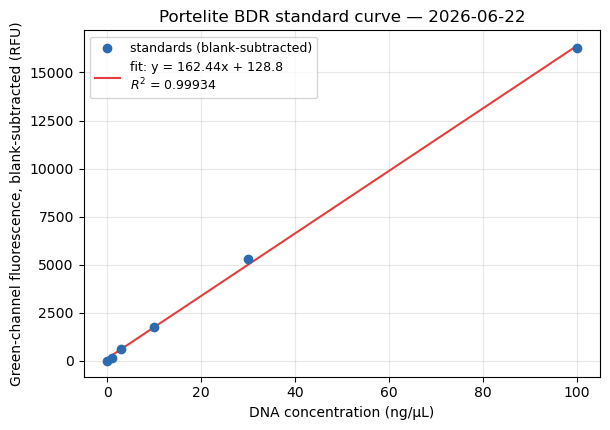

In [3]:
# Conversion helper used by Section 2: invert the fitted line, apply dilution factor.
def rfu_to_conc(rfu):
    """Raw green-channel RFU -> DNA concentration (ng/uL) in the original tube."""
    return (np.asarray(rfu, dtype=float) - BLANK_RFU - intercept) / slope * DILUTION_FACTOR

# Plot the standard curve with the fit
fig, ax = plt.subplots(figsize=(6.2, 4.4))
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'],
           color='#2b6cb0', zorder=3, label='standards (blank-subtracted)')
xline = np.linspace(0, MAX_STD_CONC, 100)
ax.plot(xline, slope * xline + intercept, color='#e53e3e', lw=1.5,
        label=f'fit: y = {slope:.2f}x + {intercept:.1f}\n$R^2$ = {r_squared:.5f}')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Green-channel fluorescence, blank-subtracted (RFU)')
ax.set_title('Portelite BDR standard curve — 2026-06-22')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 2 — Sample DNA concentrations

Convert each raw reading to ng/µL via the fitted curve. All 18 samples are Round-2
bacteria-genome extracts (extracted 2026-06-10). `extrapolated = True` would flag any sample
above the 100 ng/µL top standard — none are this session.

In [4]:
# Raw green-channel readings, 2026-06-22 (undiluted). 18 Round-2 bacteria-genome extracts.
# NOTE: the 2nd '6-6-2' on the bench list (2284.72) is '6-2-2' (user-confirmed 2026-06-22).
samples = pd.DataFrame([
    ('9-9-2',   5863.49),
    ('6-2-1',   5370.16),
    ('6-8-2',   3692.72),
    ('6-10-2',  9343.18),
    ('8-10-2', 11774.60),
    ('9-10-1',  7053.49),
    ('6-8-1',   4896.63),
    ('9-1-1',  13525.83),
    ('8-1-2',   8706.86),
    ('10-9-1',  3200.50),
    ('8-7-1',   2693.19),
    ('6-6-2',   6949.00),
    ('9-1-2',   6702.02),
    ('6-2-2',   2284.72),   # recorded as a 2nd '6-6-2' on the bench list; corrected to 6-2-2
    ('10-10-1', 1296.26),
    ('10-7-2',  1570.95),
    ('6-7-2',    989.73),
    ('6-6-1',  10163.27),
], columns=['sample', 'rfu'])

samples['conc_ng_uL'] = rfu_to_conc(samples['rfu'])
samples['extrapolated'] = samples['conc_ng_uL'] > MAX_STD_CONC

with pd.option_context('display.float_format', lambda v: f'{v:,.2f}'):
    print(samples[['sample', 'rfu', 'conc_ng_uL', 'extrapolated']].to_string(index=False))
print(f"\nSamples above the 100 ng/uL top standard (extrapolated): "
      f"{int(samples['extrapolated'].sum())} of {len(samples)}")

 sample       rfu  conc_ng_uL  extrapolated
  9-9-2  5,863.49       34.35         False
  6-2-1  5,370.16       31.31         False
  6-8-2  3,692.72       20.99         False
 6-10-2  9,343.18       55.77         False
 8-10-2 11,774.60       70.74         False
 9-10-1  7,053.49       41.68         False
  6-8-1  4,896.63       28.40         False
  9-1-1 13,525.83       81.52         False
  8-1-2  8,706.86       51.85         False
 10-9-1  3,200.50       17.96         False
  8-7-1  2,693.19       14.83         False
  6-6-2  6,949.00       41.03         False
  9-1-2  6,702.02       39.51         False
  6-2-2  2,284.72       12.32         False
10-10-1  1,296.26        6.23         False
 10-7-2  1,570.95        7.92         False
  6-7-2    989.73        4.35         False
  6-6-1 10,163.27       60.82         False

Samples above the 100 ng/uL top standard (extrapolated): 0 of 18


### Section 2 plots — concentration per sample, and samples on the curve

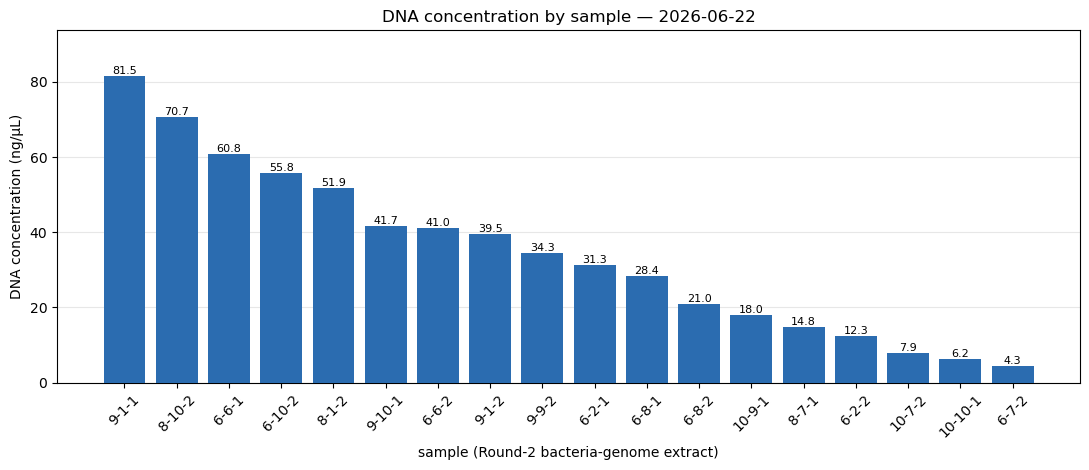

In [5]:
# Bar chart: DNA concentration per sample (sorted high -> low), extrapolated bars hatched.
from matplotlib.patches import Patch

df = samples.sort_values('conc_ng_uL', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 4.8))
bars = ax.bar(df['sample'], df['conc_ng_uL'], color='#2b6cb0', zorder=3)
for bar, extrap in zip(bars, df['extrapolated']):
    if extrap:
        bar.set_hatch('//'); bar.set_edgecolor('#c53030')
for bar, val in zip(bars, df['conc_ng_uL']):
    ax.text(bar.get_x() + bar.get_width() / 2, val, f'{val:.1f}',
            ha='center', va='bottom', fontsize=8)
ax.set_ylabel('DNA concentration (ng/µL)')
ax.set_xlabel('sample (Round-2 bacteria-genome extract)')
ax.set_title('DNA concentration by sample — 2026-06-22')
ax.tick_params(axis='x', rotation=45)
ax.margins(y=0.15); ax.grid(axis='y', alpha=0.3)
if samples['extrapolated'].any():
    ax.legend(handles=[Patch(facecolor='#2b6cb0', hatch='//', edgecolor='#c53030',
                             label='extrapolated (> 100 ng/µL top std)')],
              fontsize=8, loc='upper right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_concentration-by-sample.png'),
            dpi=150, bbox_inches='tight')
plt.show()

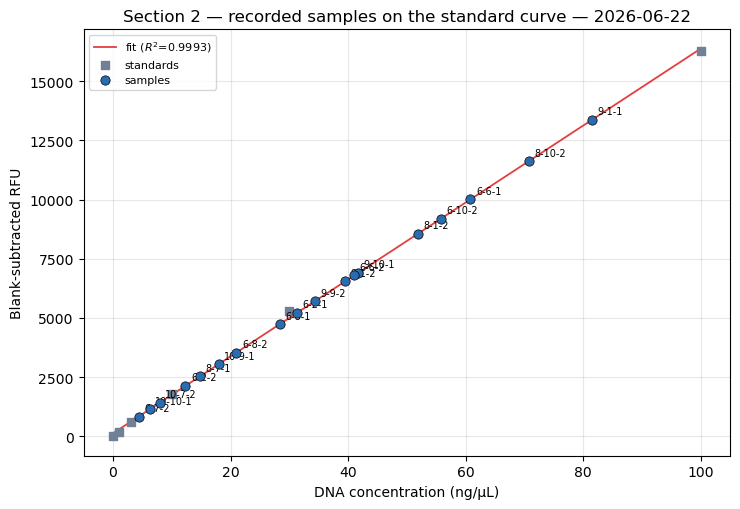

In [6]:
# Place each recorded sample on the standard curve at (conc, blank-subtracted RFU).
fig, ax = plt.subplots(figsize=(7.5, 5.2))
xmax = max(samples['conc_ng_uL'].max() * 1.10, MAX_STD_CONC)
xs = np.linspace(0, xmax, 100)
ax.plot(xs, slope * xs + intercept, color='#e53e3e', lw=1.3, zorder=2,
        label=f'fit ($R^2$={r_squared:.4f})')
ax.scatter(standards['conc_ng_uL'], standards['rfu_corrected'], color='#718096',
           marker='s', s=40, zorder=3, label='standards')
ax.scatter(samples['conc_ng_uL'], samples['rfu'] - BLANK_RFU, color='#2b6cb0', s=45,
           zorder=4, edgecolor='black', linewidth=0.5, label='samples')
for _, r in samples.iterrows():
    ax.annotate(r['sample'], (r['conc_ng_uL'], r['rfu'] - BLANK_RFU),
                textcoords='offset points', xytext=(4, 4), fontsize=7)
if xmax > MAX_STD_CONC:
    ax.axvspan(MAX_STD_CONC, xmax, color='#fed7d7', alpha=0.4, zorder=1)
    ax.axvline(MAX_STD_CONC, color='#c53030', ls='--', lw=1, zorder=2)
    ax.text(MAX_STD_CONC, ax.get_ylim()[1], ' extrapolated', color='#c53030',
            fontsize=8, va='top', ha='left')
ax.set_xlabel('DNA concentration (ng/µL)')
ax.set_ylabel('Blank-subtracted RFU')
ax.set_title('Section 2 — recorded samples on the standard curve — 2026-06-22')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f'{DATE}_samples-on-standard-curve.png'),
            dpi=150, bbox_inches='tight')
plt.show()

## Section 3 — DNA mass currently in each fridge tube

`mass = concentration (ng/µL) × remaining volume (µL)`, reported in µg. Remaining volume is
`VOL_BACTERIAL_uL` = **90 µL** (user-confirmed 2026-06-22). Adjust the parameter at the top if
the real volume differs.

In [7]:
samples['remaining_vol_uL'] = VOL_BACTERIAL_uL
samples['mass_ug'] = samples['conc_ng_uL'] * samples['remaining_vol_uL'] / 1000.0

with pd.option_context('display.float_format', lambda v: f'{v:,.3f}'):
    print(samples[['sample', 'conc_ng_uL', 'remaining_vol_uL', 'mass_ug', 'extrapolated']]
          .to_string(index=False))

print(f"\nTotal recoverable DNA (18 tubes, at {VOL_BACTERIAL_uL:.0f} uL/tube): "
      f"{samples['mass_ug'].sum():,.2f} ug")
print(f"Mean concentration: {samples['conc_ng_uL'].mean():,.2f} ng/uL  "
      f"(range {samples['conc_ng_uL'].min():,.2f} - {samples['conc_ng_uL'].max():,.2f})")

 sample  conc_ng_uL  remaining_vol_uL  mass_ug  extrapolated
  9-9-2      34.349            90.000    3.091         False
  6-2-1      31.312            90.000    2.818         False
  6-8-2      20.986            90.000    1.889         False
 6-10-2      55.771            90.000    5.019         False
 8-10-2      70.739            90.000    6.366         False
 9-10-1      41.675            90.000    3.751         False
  6-8-1      28.397            90.000    2.556         False
  9-1-1      81.520            90.000    7.337         False
  8-1-2      51.853            90.000    4.667         False
 10-9-1      17.956            90.000    1.616         False
  8-7-1      14.833            90.000    1.335         False
  6-6-2      41.032            90.000    3.693         False
  9-1-2      39.511            90.000    3.556         False
  6-2-2      12.318            90.000    1.109         False
10-10-1       6.233            90.000    0.561         False
 10-7-2       7.924     

## Readout

- **Curve:** fresh 6-point S0–S100 series; linear fit reported in Section 1 (R² printed there).
- **All 18 Round-2 bacteria-genome extracts read within the curve** (max 9-1-1 at 13,526 RFU vs
  the 16,435 RFU S100 top standard), so **no extrapolation** was needed — a cleaner read than the
  0605 bacterial set, which sat well above the top standard.
- **`6-2-2`** (the relabelled 2nd `6-6-2`) and **`6-7-2`** are the lowest of the set; **`9-1-1`**,
  **`8-10-2`** and **`6-6-1`** the highest — see the per-sample table and bar chart for exact ng/µL.
- **Mass per tube at 90 µL remaining** (user-confirmed): ~0.4–7.3 µg/tube, ~56 µg total.

---
*Log: created 2026-06-22 from bench Qubit readings (no digitalized notebook entry for this
session). 2nd `6-6-2` corrected to `6-2-2` per user; remaining volume 90 µL/tube confirmed by
user. Outputs in `output/0622_quantification/`.*